# Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights #

## Objective: 
Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management. 

## Dataset: 
This lab utilizes the Amazon UK product (https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/) dataset which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [ ]:
df = pd.read_csv("C:/Users/Kinga/Desktop/WORK/IRONHACK - SG/IRONHACK/BOOTCAMP/WEEK 5/DAY 1 20250929/amz_uk_price_prediction_dataset.csv")

In [6]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


## Part 1: Understanding Product Categories
Business Question: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. Frequency Tables:

- Generate a frequency table for the product category.
- Which are the top 5 most listed product categories?

2. Visualizations:

- Display the distribution of products across different categories using a bar chart. If you face problems understanding the chart, do it for a subset of top categories.
- For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [7]:
freq_table_category = df['category'].value_counts()

In [8]:
freq_table_category

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [9]:
top5 = df['category'].value_counts().head(5)

In [10]:
top5

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

In [30]:
top10 = df['category'].value_counts().head(10)

In [31]:
top10

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

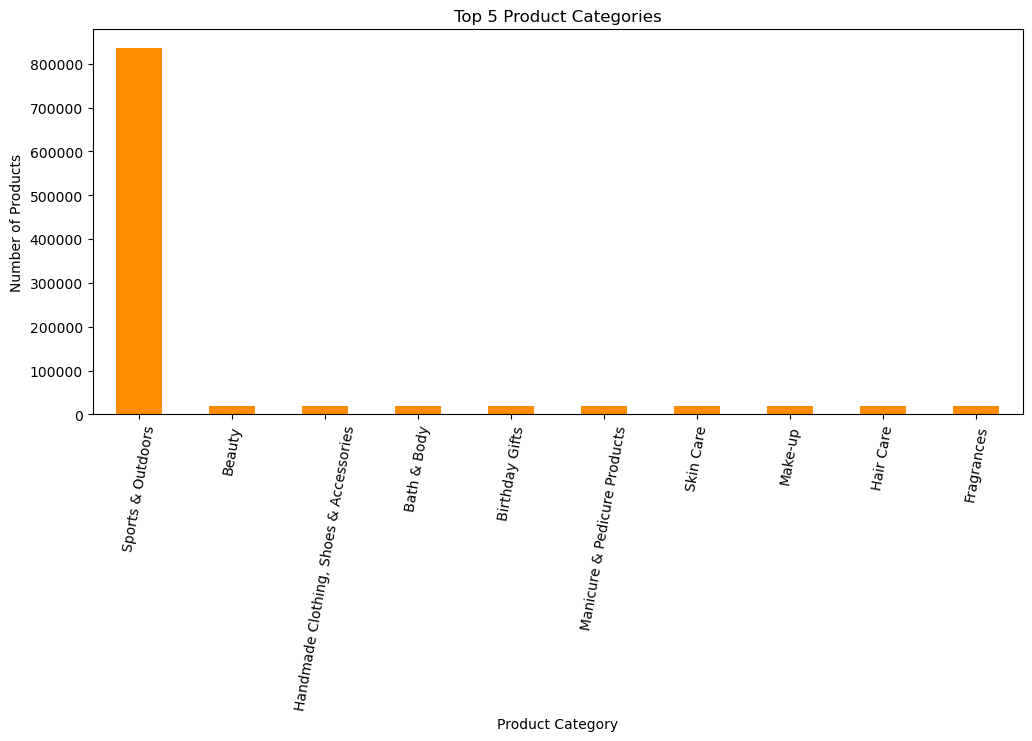

In [35]:
plt.figure(figsize=(12,5))
top10.plot(kind='bar', color='darkorange')
plt.title('Top 5 Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Number of Products')
plt.xticks(rotation=80)
plt.show()

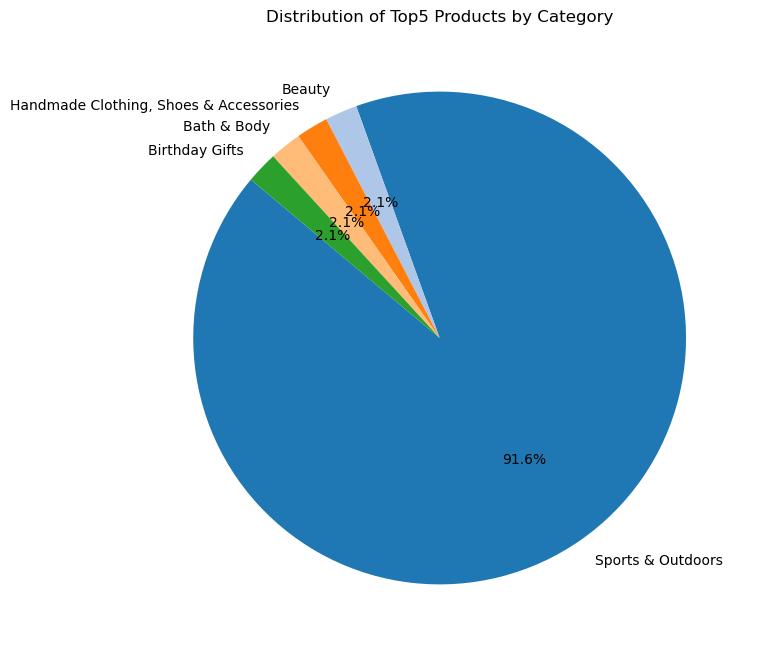

In [36]:
plt.figure(figsize=(8,8))
plt.pie(
    top5,
    labels=top5.index,
    autopct='%1.1f%%',    
    startangle=140,       
    colors=plt.cm.tab20.colors  
)
plt.title("Distribution of Top5 Products by Category")
plt.show()

## Part 2: Delving into Product Pricing
Business Question: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. Measures of Centrality:

- Calculate the mean, median, and mode for the price of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?
  
2. Measures of Dispersion:

- Determine the variance, standard deviation, range, and interquartile range for product price.
- How varied are the product prices? Are there any indicators of a significant spread in prices?

3. Visualizations:

- Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. If its hard to read these diagrams, think why this is, and explain how it could be solved..
- Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [37]:
# Mean
mean_price = df['price'].mean()

# Median
median_price = df['price'].median()

# Mode
mode_price = df['price'].mode() 

In [38]:
print(f"Mean Price: {mean_price}")
print(f"Median Price: {median_price}")
print(f"Mode Price(s): {list(mode_price)}")

Mean Price: 89.24380943923663
Median Price: 19.09
Mode Price(s): [9.99]


In [39]:
average_price = df['price'].mean()

print(f"Average Price: {average_price}")

Average Price: 89.24380943923663


Average price is much higher tahn mode price (almost 10x higher)

In [41]:
# Variance
variance_price = df['price'].var()  

# Standard Deviation
std_dev_price = df['price'].std()  

# Range
range_price = df['price'].max() - df['price'].min()

# Interquartile Range (IQR)
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
iqr_price = Q3 - Q1

In [42]:
print(f"Variance: {variance_price}")
print(f"Standard Deviation: {std_dev_price}")
print(f"Range: {range_price}")
print(f"Interquartile Range (IQR): {iqr_price}")

Variance: 119445.48532256528
Standard Deviation: 345.60886175352226
Range: 100000.0
Interquartile Range (IQR): 36.0


The product prices are highly varied, with most products clustered in a narrow range, but a few extremely high-priced items create a large spread. This is reflected in the very high variance, standard deviation, and range, while the interquartile range remains relatively small. Overall, the spread is driven by outliers rather than the typical product prices.

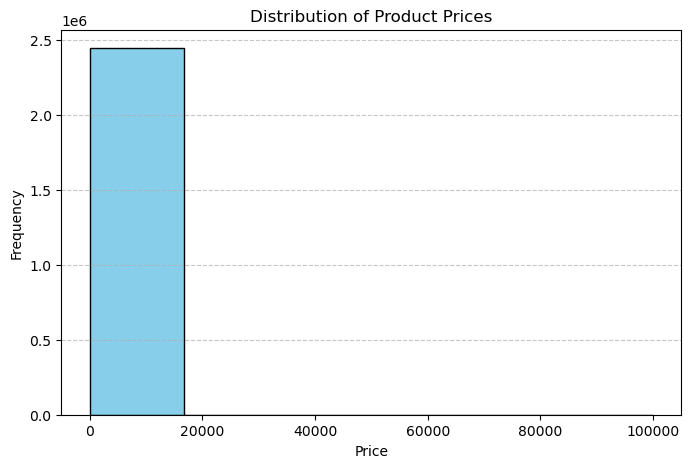

In [48]:
plt.figure(figsize=(8,5))
plt.hist(df['price'], bins=6, color='skyblue', edgecolor='black')
plt.title('Distribution of Product Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The histogram may look skewed or compressed at the lower end because the extreme outlier (100,000) stretches the x-axis. Most bars representing normal prices are hard to see.

Solutions:

- Excluding or separate outliers when plotting to focus on typical prices

- Using a log scale on the x-axis to compress extreme values while preserving distribution

- Adjusting bins to better visualize where most products fall

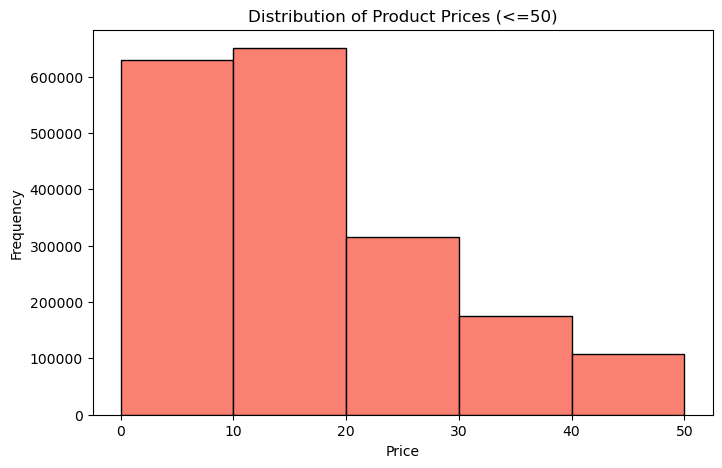

In [49]:
# Focusing only on prices ≤ 50

plt.figure(figsize=(8,5))
plt.hist(df[df['price']<=50]['price'], bins=5, color='salmon', edgecolor='black')
plt.title('Distribution of Product Prices (<=50)')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

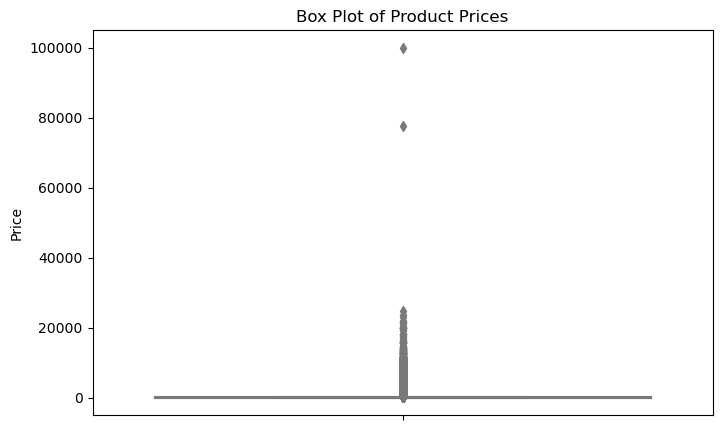

In [50]:
plt.figure(figsize=(8,5))
sns.boxplot(y=df['price'], color='lightblue')
plt.title('Box Plot of Product Prices')
plt.ylabel('Price')
plt.show()


## Part 3: Unpacking Product Ratings
Business Question: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. Measures of Centrality:

- Calculate the mean, median, and mode for the rating of products.
- How do customers generally rate products? Is there a common trend?

2. Measures of Dispersion:

- Determine the variance, standard deviation, and interquartile range for product rating.
- Are the ratings consistent, or is there a wide variation in customer feedback?

3. Shape of the Distribution:

- Calculate the skewness and kurtosis for the rating column.
- Are the ratings normally distributed, or do they lean towards higher or lower values?

4. Visualizations:

- Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [51]:
# Mean
mean_rating = df['stars'].mean()

# Median
median_rating = df['stars'].median()

# Mode
mode_rating = df['stars'].mode()  

In [52]:
print(f"Mean Rating: {mean_rating}")
print(f"Median Rating: {median_rating}")
print(f"Mode Rating(s): {list(mode_rating)}")

Mean Rating: 2.152836472966065
Median Rating: 0.0
Mode Rating(s): [0.0]


Customers generally rate products very low, with most ratings being 0. This is reflected in the mean rating of about 2.15, the median of 0, and the mode also being 0. Overall, the ratings indicate a strong tendency toward very low scores.

In [53]:
# Variance
variance_rating = df['stars'].var()

# Standard Deviation
std_dev_rating = df['stars'].std()

# Interquartile Range (IQR)
Q1 = df['stars'].quantile(0.25)
Q3 = df['stars'].quantile(0.75)
iqr_rating = Q3 - Q1

In [54]:
print(f"Variance: {variance_rating}")
print(f"Standard Deviation: {std_dev_rating}")
print(f"Interquartile Range (IQR): {iqr_rating}")

Variance: 4.81743402976196
Standard Deviation: 2.1948653785054697
Interquartile Range (IQR): 4.4


The customer ratings show a wide variation, as indicated by the relatively high variance and standard deviation. While the interquartile range of 4.4 shows that the middle 50% of ratings are somewhat spread out, the presence of extreme values contributes to the overall inconsistency. Overall, feedback is not consistent and varies significantly across products.

In [56]:
from scipy.stats import skew, kurtosis

In [57]:
# Skewness
skewness_rating = skew(df['stars'])

# Kurtosis
kurtosis_rating = kurtosis(df['stars'])


In [58]:
print(f"Skewness: {skewness_rating}")
print(f"Kurtosis: {kurtosis_rating}")

Skewness: 0.08120730776283354
Kurtosis: -1.926004642549839


### Skewness measures the asymmetry of the distribution:

s> 0 → right-skewed (tail on the right)

s< 0 → left-skewed (tail on the left)

s≈ 0 → roughly symmetric

### Kurtosis measures the tailedness (peakedness) of the distribution:

s> 0 → heavy tails, more outliers than normal distribution

s< 0 → light tails, fewer outliers

s≈ 0 → similar to normal distribution

The ratings are roughly symmetric, as indicated by the skewness close to 0, but the negative kurtosis suggests the distribution is flatter than a normal distribution. This means there are fewer extreme values in the tails and more ratings spread around the center. Overall, ratings tend to cluster around lower values but without heavy outliers.

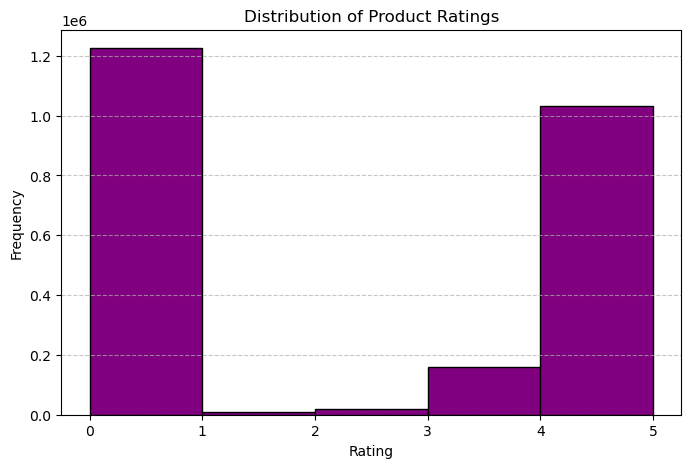

In [59]:
plt.figure(figsize=(8,5))
plt.hist(df['stars'], bins=5, color='purple', edgecolor='black')
plt.title('Distribution of Product Ratings')
plt.xlabel('Rating')
plt.ylabel('Frequency')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The most common ratings are the lowest (0), the highest (5), and 4, indicating a polarized trend in customer feedback. This pattern suggests that many customers either had very negative or very positive experiences, while a smaller group gave moderately high ratings. Such a distribution often occurs when products elicit strong opinions, either highly satisfying or disappointing users.